# Master
All the features from DFT(harmonised), ONS, and Energy datasets will be merged to form a master dataset before the Accessibility Inequality Metric is developed. This is followed by Predictive Modelling alongwith SHAP Analysis.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

employment = pd.read_excel("Harmonised DFT Datasets/employmentcentres_features2021.xlsx") ## features related to access to Employment Centres
food = pd.read_excel("Harmonised DFT Datasets/food_store_features2021.xlsx") ## features related to access to Food Stores
gp = pd.read_excel("Harmonised DFT Datasets/gp_accessibility_features2021.xlsx") ## features related to access to GPs
hospital = pd.read_excel("Harmonised DFT Datasets/hospital_accessibility_features2021.xlsx") ## features related to access to Hospitals
town = pd.read_excel("Harmonised DFT Datasets/town_centre_features2021.xlsx") ## features related to access to town centres

car_access= pd.read_excel("ONS Datasets/car_availability_features_LSOA.xlsx") ## features related to household car access
rural = pd.read_excel("ONS Datasets/rural_urban_features.xlsx") ## features related to rural urban accessibility
popdensity = pd.read_excel("ONS Datasets/popdensity_features.xlsx") ##features related to Population Density

fuel = pd.read_excel("Energy Datasets/annual_fuel_features_2022_2023.xlsx") ##features related to annual fuel prices for year 2022 and 2023

## Dataset Integration

Renaming the LSOA code names all datasets to LS0A21CD

In [3]:
car_access["LSOA21CD"] = car_access["LSOA_code"]
rural["LSOA21CD"] = rural["LSOA_code"]
popdensity["LSOA21CD"] = popdensity["LSOA_code"]

In [4]:
#one row per LSOA before merging.
datasets = {
    "Employment": employment,
    "Food": food,
    "GP": gp,
    "Hospital": hospital,
    "Town": town,
    "Car_Access": car_access,
    "Rural/Urban": rural,
    "Population Density": popdensity
}

for name, df in datasets.items():
    print(
        name,
        "Rows:", len(df),
        "Unique LSOAs:", df["LSOA21CD"].nunique(),
        "Duplicates:", df["LSOA21CD"].duplicated().sum()
    )

Employment Rows: 32747 Unique LSOAs: 32747 Duplicates: 0
Food Rows: 32747 Unique LSOAs: 32747 Duplicates: 0
GP Rows: 32747 Unique LSOAs: 32747 Duplicates: 0
Hospital Rows: 32747 Unique LSOAs: 32747 Duplicates: 0
Town Rows: 32747 Unique LSOAs: 32747 Duplicates: 0
Car_Access Rows: 33755 Unique LSOAs: 33755 Duplicates: 0
Rural/Urban Rows: 33755 Unique LSOAs: 33755 Duplicates: 0
Population Density Rows: 35672 Unique LSOAs: 35672 Duplicates: 0


In [5]:
employment_m = employment[
    [
        "LSOA21CD",
        "employment_pt_time",      ## Travel time in minutes to nearest Employment centre by Public Transport
        "employment_car_time",     ## Travel time in minutes to nearest Employment centre by Car
        "employment_pt_car_gap",   ## Travel time difference in minutes to nearest Employment centre between car and Public transport
        "employment_pt_30min_pct"  ## % of users within 30minutes of employment centres by Public Transport
    ]
]
food_m = food[
    [
        "LSOA21CD",               
        "FoodPTt",                ## Travel time in minutes to nearest Food Store by Public Transport
        "FoodPT30pct",            ## % of users within 30minutes of Food Stores by Public Transport
        "FoodWalkt",              ## Travel time in minutes to nearest Food Store by Walking
        "FoodCart",               ## Travel time in minutes to nearest Food Store by Car
        "Food_PT_Car_Gap"         ## Travel time difference in minutes to nearest Food Store between car and Public transport
    ]
]
hospital_m = hospital[
    [
        "LSOA21CD",              
        "HospPTt",               ## Travel time in minutes to nearest Hospital by Public Transport
        "HospCart",              ## Travel time in minutes to nearest Hospital by Car
        "HospPT30pct",           ## % of users within 30minutes of Hospital by Public Transport
        "Hosp_PT_Car_Gap"        ## Travel time difference in minutes to nearest Hospital between car and Public transport
    ]
]
gp_m = gp[
    [   #exclude GP_pop here because we already have dedicated ONS population-density feature
        "LSOA21CD",
        "GPPTt",                ## Travel time in minutes to nearest GP by Public Transport
        "GPCart",               ## Travel time in minutes to nearest GP by Car
        "GPWalkt",              ## Travel time in minutes to nearest GP by Walking
        "GPPT30pct",            ## % of users within 30minutes of GP by Public Transport
        "GP_PT_Car_Gap"         ## Travel time difference in minutes to nearest GP between car and Public transport
    ]
]
town_m = town[
    [
        "LSOA21CD",            
        "TownPTt",             ## Travel time in minutes to nearest Town Centre by Public Transport 
        "TownPT30pct",         ## % of users within 30minutes of Town Centre by Public Transport
        "Town_PT_Car_gap"      ## Travel time difference in minutes to nearest Town Centre between car and Public transport
    ]
]
caraccess_m = car_access[
    ["LSOA21CD", "No_car_pct"]  ##No_car_pct refers to percentage of people with no access to cars
]

rural_m = rural[
    ["LSOA21CD", "RUC21NM", "Urban_rural_flag", "rural_flag"]  ##Urban_rural_flag: Object type classification as "urban" or "rural" for each LSOA region
]                                                              ##rural_flag: Integer data type where rural is 1 and urban is 0 for each LSOA region

popdensity_m = popdensity[
    ["LSOA21CD", "Observation", "population_density_log"]  ##Observation: Population Density and population_density_log: Logarithmic Population density for each LSOA regions
]

MERGING

In [6]:
master = employment_m.copy()

master = master.merge(
    food_m,
    on="LSOA21CD",
    how="left",
    validate="one_to_one"
)
master = master.merge(
    gp_m,
    on="LSOA21CD",
    how="left",
    validate="one_to_one"
)

master = master.merge(
    hospital_m,
    on="LSOA21CD",
    how="left",
    validate="one_to_one"
)

master = master.merge(
    town_m,
    on="LSOA21CD",
    how="left",
    validate="one_to_one"
)

master = master.merge(
    caraccess_m,
    on="LSOA21CD",
    how="left",
    validate="one_to_one"
)

master = master.merge(
    rural_m,
    on="LSOA21CD",
    how="left",
    validate="one_to_one"
)

master = master.merge(
    popdensity_m,
    on="LSOA21CD",
    how="left",
    validate="one_to_one"
)

In [7]:
print(master.shape)
print(master["LSOA21CD"].nunique())

(32747, 28)
32747


In [8]:
master.info()

<class 'pandas.DataFrame'>
RangeIndex: 32747 entries, 0 to 32746
Data columns (total 28 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   LSOA21CD                 32747 non-null  str    
 1   employment_pt_time       32747 non-null  float64
 2   employment_car_time      32747 non-null  float64
 3   employment_pt_car_gap    32747 non-null  float64
 4   employment_pt_30min_pct  32747 non-null  float64
 5   FoodPTt                  32747 non-null  float64
 6   FoodPT30pct              32747 non-null  float64
 7   FoodWalkt                32747 non-null  float64
 8   FoodCart                 32747 non-null  float64
 9   Food_PT_Car_Gap          32747 non-null  int64  
 10  GPPTt                    32747 non-null  float64
 11  GPCart                   32747 non-null  float64
 12  GPWalkt                  32747 non-null  float64
 13  GPPT30pct                32747 non-null  float64
 14  GP_PT_Car_Gap            32747 no

In [9]:
missing = pd.DataFrame({
    "Missing": master.isna().sum(),
    "Missing_pct": master.isna().mean() * 100
}).sort_values("Missing_pct", ascending=False)

missing

,Missing,Missing_pct
LSOA21CD,0,0.0
employment_pt_time,0,0.0
employment_car_time,0,0.0
employment_pt_car_gap,0,0.0
employment_pt_30min_pct,0,0.0
FoodPTt,0,0.0
FoodPT30pct,0,0.0
FoodWalkt,0,0.0
FoodCart,0,0.0
Food_PT_Car_Gap,0,0.0


above code calculates and displays the count and percentage of missing values (NaN/Null) for every column in your master DataFrame, sorted from most missing to least

In [10]:
print("Rows:", len(master))
print("Unique LSOAs:", master["LSOA21CD"].nunique())
print("Duplicate LSOAs:", master["LSOA21CD"].duplicated().sum())
#master.describe().T

Rows: 32747
Unique LSOAs: 32747
Duplicate LSOAs: 0


## EDA

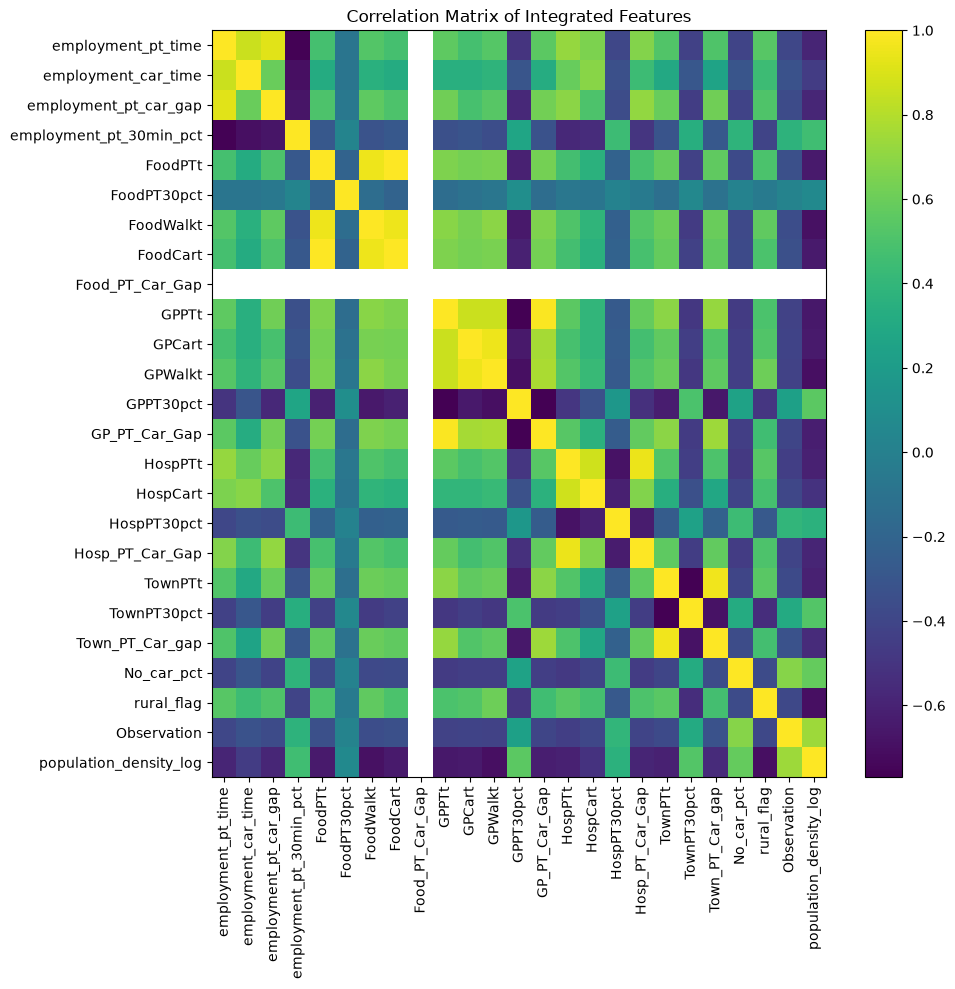

In [11]:
# Correlation between different features (of numerical datatypes)
numeric_cols = master.select_dtypes(include=np.number).columns

corr = master[numeric_cols].corr()

plt.figure(figsize=(10, 10))
plt.imshow(corr, aspect="auto")
plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=90
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Correlation Matrix of Integrated Features")
plt.tight_layout()
plt.show()

High positive correlations (bright yellow blocks) form clear clusters within service such as primary care (GPPTt, GPCart, GPWalkt) and food stores (FoodPTt, FoodWalkt, FoodCart) showing that proximity across modes is heavily dictated by underlying geography. Food_PT_Car_Gap appears completely blank (white row/column), values in that column is all zero. Need to avoid that valuable feature going forward

In [12]:
master.groupby("Urban_rural_flag")[
    [   "employment_pt_time", #time to reach Exmployment centre via Public Transport
        "GPPTt",              #time to reach nearby GP via Public Transport
        "HospPTt",            #time to reach Hospital via Public Transport
        "TownPTt",            #time to reach Town_Centre via Public Transport
        "FoodPTt",            #time to reach Food_stores via Public Transport
        "No_car_pct"          #%o of households with no access to Car
    ]].mean()

,employment_pt_time,GPPTt,HospPTt,TownPTt,FoodPTt,No_car_pct
Urban_rural_flag,,,,,,
Rural,55.708707,23.080670,66.291528,35.134033,8.872680,10.254670
Urban,27.103452,11.219285,36.317028,17.703553,6.761865,25.528874


The fuel data is a single NATIONAL series (one price per year), so a cross join would duplicate every LSOA once per year while leaving accessibilities features identical between the copies. That fabricates the shape of panel data without adding any information, and it leaks near-identical rows across the train/test split during modelling.
The two years are therefore treated as price scenarios (columns), not as extra observations (rows). As shown below


In [13]:
master_df = master.copy()

fuel_lookup = fuel.set_index("Year")["Average_Fuel_Price"].sort_index()
years = fuel_lookup.index.tolist()

print("Rows:", len(master_df))
print("Unique LSOAs:", master_df["LSOA21CD"].nunique())
print("Duplicate LSOAs:", master_df["LSOA21CD"].duplicated().sum())
print("\nNational average fuel price by year:")
print(fuel_lookup)

Rows: 32747
Unique LSOAs: 32747
Duplicate LSOAs: 0

National average fuel price by year:
Year
2022    171.210288
2023    152.887212
Name: Average_Fuel_Price, dtype: float64


## Determining Accessibility Inequality Metric

For the proposed Transport Accessibility Inequality metric (AIM), 
the formula is conceptualised as

AIM is based on 3 factors- PoorAccessibility(mentioned in feature as Access Disadvantage), CarDependency and MobilityCostExposure

where a higher AIM represents greater transport accessibility inequality/disadvantage for each LSOA

1. FOR Poor Accessibility:

Access to locations within 30mins (threshold) via public trnasport

In [14]:
access_cols = [
    'employment_pt_30min_pct',
    'FoodPT30pct',
    'GPPT30pct',
    'HospPT30pct',
    'TownPT30pct'
]

The indicators have different distributions/scales, so standardise before combining them.

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

access_z = pd.DataFrame(
    scaler.fit_transform(master_df[access_cols]),
    columns=[f'{col}_z' for col in access_cols],
    index=master_df.index
)

Convert accessibility into disadvantage. higher access_disadvantage indicates poorer accessibility to essential destinations.

In [16]:
access_disadvantage = -access_z
master_df['access_disadvantage'] = access_disadvantage.mean(axis=1)

2. FOR CAR DEPENDENCY

Standardise the appropriate car-access percentage. Using Z score

In [17]:
master_df['car_access_pct']= 100- master_df["No_car_pct"]
master_df['car_access_z'] = (master_df['car_access_pct']- master_df['car_access_pct'].mean()) / master_df['car_access_pct'].std()

High car ownership by itself does not necessarily mean inequality. A stronger measure is the interaction between poor public-transport accessibility and car dependence. Mathematically this is done by multiplting these two variables

In [18]:
master_df['car_dependency'] = (master_df['car_access_pct'] / 100)

3. Mobility Cost Exposure

Average Fuel Price is used to consider both Petrol and Diesel Price collectively.
The fuel baseline is the **annual average** price for the first year of the analysis
period (2022).

In [19]:
baseline_year = min(years)
fuel_baseline = fuel_lookup.loc[baseline_year]

print("Baseline year:", baseline_year)
print("Baseline average fuel price:", fuel_baseline)

Baseline year: 2022
Baseline average fuel price: 171.2102884615385


Fuel Price Index is used to represent how much the average fuel price changed relative to fuel baseline

In [20]:
fuel_price_index = fuel_lookup / fuel_baseline

Cost Exposure for mobility is determined by the interaction of 2 factors here, car dependency and fuel price index

In [21]:
# Cost exposure under each year's price regime.
# car_dependency is fixed; only the price multiplier changes.
for yr in years:
    master_df[f"cost_exposure_{yr}"] = (
        master_df["car_dependency"] * fuel_price_index.loc[yr]
    )

master_df[[f"cost_exposure_{yr}" for yr in years]].describe().T




,count,mean,std,min,25%,50%,75%,max
cost_exposure_2022,32747.0,0.770043,0.156003,0.131669,0.685114,0.811268,0.892960,0.993590
cost_exposure_2023,32747.0,0.687632,0.139308,0.117577,0.611793,0.724445,0.797394,0.887255


In [22]:
# Access disadvantage does not vary by year, so it is standardised once.
master_df["access_disadvantage_z"] = (
    master_df["access_disadvantage"] - master_df["access_disadvantage"].mean()
) / master_df["access_disadvantage"].std()

# Cost exposure is standardised against the Baseline Year(2022)'s mean and standard deviation, not against each year separately. 
# Standardising each year on its own would force both years to mean 0 and remove precisely the year-on-year shift being measured.
base_mu = master_df[f"cost_exposure_{baseline_year}"].mean()
base_sd = master_df[f"cost_exposure_{baseline_year}"].std()

for yr in years:
    master_df[f"cost_exposure_{yr}_z"] = (
        master_df[f"cost_exposure_{yr}"] - base_mu
    ) / base_sd

master_df[["access_disadvantage_z"] +
          [f"cost_exposure_{yr}_z" for yr in years]].describe().T

,count,mean,std,min,25%,50%,75%,max
access_disadvantage_z,32747.0,2.777337e-17,1.000000,-1.018420,-0.774317,-0.276392,0.435039,30.242815
cost_exposure_2022_z,32747.0,3.888272e-16,1.000000,-4.092056,-0.544403,0.264254,0.787911,1.432960
cost_exposure_2023_z,32747.0,-5.282623e-01,0.892979,-4.182383,-1.014403,-0.292289,0.175325,0.751341


In [23]:
# AIM under each price regime
for yr in years:
    master_df[f"AIM_{yr}"] = (
        master_df["access_disadvantage_z"] + master_df[f"cost_exposure_{yr}_z"]
    ) / 2

# Year-on-year shift in inequality attributable to the fuel price change
master_df["AIM_change"] = (
    master_df[f"AIM_{max(years)}"] - master_df[f"AIM_{baseline_year}"]
)

# Primary target for the descriptive and predictive work: the baseline year.
target_year = baseline_year
master_df["accessibility_inequality_metric"] = master_df[f"AIM_{target_year}"]

print(f"Modelling target = AIM_{target_year}")
master_df[[f"AIM_{yr}" for yr in years] + ["AIM_change"]].describe().T

Modelling target = AIM_2022


,count,mean,std,min,25%,50%,75%,max
AIM_2022,32747.0,2.221870e-16,0.855262,-2.555238,-0.511561,0.026162,0.511836,15.711518
AIM_2023,32747.0,-2.641311e-01,0.809971,-2.600401,-0.752469,-0.251350,0.214368,15.384233
AIM_change,32747.0,-2.641311e-01,0.053510,-0.340809,-0.306293,-0.278271,-0.235000,-0.045163


AIM_2022 acts as a standardized baseline with a mean near zero (2.221870e-16) and standard deviation around 0.855, reflecting balanced z-score aggregation across England's LSOAs.
AIM_2023 and AIM_change exhibit a negative mean shift (-0.264), demonstrating that falling fuel prices from 2022 to 2023 systematically reduced transport-cost vulnerability across all regions.
Despite the average decline in vulnerability, maximum values remain extremely high ( 15.38 to 15.71), showing that deeply disadvantaged, low-density LSOAs face severe structural inequality regardless of yearly fuel price fluctuations.

Categorizes English neighborhoods (LSOAs) into five equal tiers based on their inequality scores and outputs a statistical summary of the results from Very Low to Very High

In [24]:
master_df['inequality_quintile'] = pd.qcut(
    master_df['accessibility_inequality_metric'],
    q=5,
    labels=[
        'Very Low',
        'Low',
        'Moderate',
        'High',
        'Very High'
    ]
)
master_df[
    ['accessibility_inequality_metric',
     'inequality_quintile']
].describe(include='all')

,accessibility_inequality_metric,inequality_quintile
count,3.274700e+04,32747
unique,NaN,5
top,NaN,Very Low
freq,NaN,6551
mean,2.221870e-16,NaN
std,8.552619e-01,NaN
min,-2.555238e+00,NaN
25%,-5.115612e-01,NaN
50%,2.616205e-02,NaN
75%,5.118365e-01,NaN


Distribution Plot

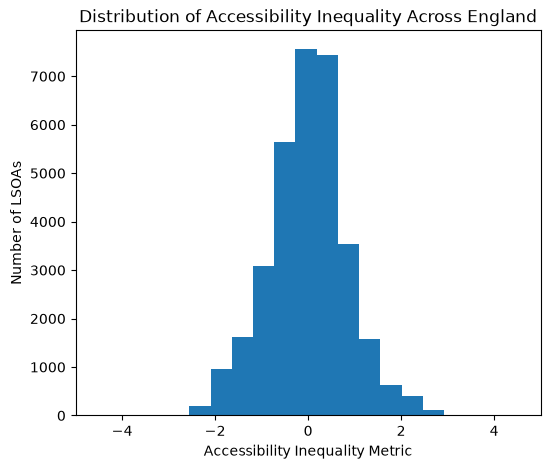

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,5))

plt.hist(
    master_df['accessibility_inequality_metric'],
    bins=40
)
plt.xlim(-5, 5)
plt.xlabel('Accessibility Inequality Metric')
plt.ylabel('Number of LSOAs')
plt.title('Distribution of Accessibility Inequality Across England')

plt.show()

1. Negative AIM: relatively lower accessibility disadvantage.
2. Around 0: approximately average accessibility conditions across England.
3. Positive AIM: relatively greater accessibility inequality/disadvantage.
4. Large positive AIM (e.g. >2): Regions(LSOAs) experiencing particularly high disadvantage according to your metric

In [26]:
print("Master dataset shape:", master_df.shape)

print("Total rows:", len(master_df))

print("Unique LSOAs:", master_df['LSOA21CD'].nunique())

print("Duplicate LSOA rows:",
      master_df.duplicated(subset=['LSOA21CD']).sum())

Master dataset shape: (32747, 42)
Total rows: 32747
Unique LSOAs: 32747
Duplicate LSOA rows: 0


SKEWNESS

In [27]:
print(
    "Skewness:",
    master_df['accessibility_inequality_metric'].skew()
)

print(
    "Missing values:",
    master_df['accessibility_inequality_metric'].isna().sum()
)

Skewness: 0.7356433727717352
Missing values: 0


Skewness evaluates data quality and structural asymmetry in the target variable (accessibility_inequality_metric). Zero missing values and revealing a right-skewed distribution driven by severe access penalties. In practical terms, while the vast majority of English LSOAs cluster symmetrically near the national average, a pronounced right-hand tail highlights a vulnerable minority of neighborhoods facing compounding spatial and cost disadvantages.

Measuring this skewness is critical for modelling, as significant positive asymmetry signals that standard regression algorithms may require log transformations, scaling, or robust loss functions to handle extreme outliers effectively

Highest AIM Value

In [28]:
master_df.nlargest(
    10,
    'accessibility_inequality_metric'
)[[
    'LSOA21CD',
    'accessibility_inequality_metric'
]]

,LSOA21CD,accessibility_inequality_metric
18237,E01019229,15.711518
26367,E01027773,13.495007
26395,E01027803,11.938054
26060,E01027447,11.084318
13306,E01014020,10.002196
26358,E01027764,9.276073
25990,E01027375,9.202386
18093,E01019077,9.201725
18121,E01019107,8.832869
18343,E01019339,8.257480


Lowest AIM Value

In [29]:
master_df.nsmallest(
    10,
    'accessibility_inequality_metric'
)[[
    'LSOA21CD',
    'accessibility_inequality_metric'
]]

,LSOA21CD,accessibility_inequality_metric
31767,E01033711,-2.555238
897,E01000937,-2.524855
818,E01000855,-2.514290
31764,E01033708,-2.505207
817,E01000853,-2.460873
4481,E01004735,-2.446770
31058,E01032739,-2.437597
31059,E01032740,-2.432712
4480,E01004734,-2.430817
31763,E01033706,-2.416796


In [30]:
print("99th percentile:", master_df['accessibility_inequality_metric'].quantile(0.99))

99th percentile: 2.216943388708645


In [31]:
print("Access disadvantage skewness:",
      master_df["access_disadvantage"].skew())

print(f"Cost exposure ({baseline_year}) skewness:",
      master_df[f"cost_exposure_{baseline_year}"].skew())

Access disadvantage skewness: 4.311401538204059
Cost exposure (2022) skewness: -1.105458432308472


Quintile Construction

In [32]:
master_df['inequality_quintile'].value_counts().sort_index()

inequality_quintile
Very Low     6551
Low          6548
Moderate     6549
High         6549
Very High    6550
Name: count, dtype: int64

In [33]:
master_df.groupby('Urban_rural_flag')['accessibility_inequality_metric'].agg(['mean', 'median', 'std', 'count'])

,mean,median,std,count
Urban_rural_flag,,,,
Rural,1.054111,0.967525,0.775516,5431
Urban,-0.209580,-0.127089,0.701783,27316


### Effect of the 2022 to 2023 fuel price change

Because the accessibility data is a single 2021 cross-section, the only quantity
that varies over time is the national fuel price. 

The temporal question **which LSOAs were most exposed to the price shift**. 
That exposure is driven entirely by car dependency: places where a high share of households depend on a car absorb more of any price move.

count    32747.000000
mean        -0.264131
std          0.053510
min         -0.340809
25%         -0.306293
50%         -0.278271
75%         -0.235000
max         -0.045163
Name: AIM_change, dtype: float64


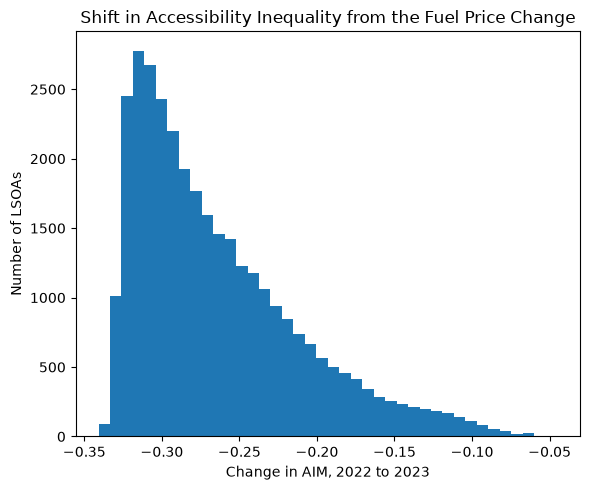

In [34]:
# Distribution of the year-on-year shift
print(master_df["AIM_change"].describe())

plt.figure(figsize=(6,5))
plt.hist(master_df["AIM_change"], bins=40)
plt.xlabel(f"Change in AIM, {baseline_year} to {max(years)}")
plt.ylabel("Number of LSOAs")
plt.title("Shift in Accessibility Inequality from the Fuel Price Change")
plt.tight_layout()
plt.show()

Every single LSOA exhibits a negative change (ranging from roughly -0.34 to -0.05), proving that the cooling of fuel prices from 2022 to 2023 provided nationwide relief from transport-cost vulnerability. A right-hand tail stretching toward 0.05 shows that while relief was widespread, the extent of improvement varied, with some areas experiencing more modest reductions in their vulnerability index.

In [35]:
# Who is most exposed to the price shift?
master_df.groupby("Urban_rural_flag")[
    ["AIM_change", "car_dependency"]
].agg(["mean", "std", "count"]).round(4)

AIM_change                car_dependency               
                       mean     std  count           mean     std  count
Urban_rural_flag                                                        
Rural               -0.3078  0.0208   5431         0.8975  0.0606   5431
Urban               -0.2554  0.0538  27316         0.7447  0.1568  27316

Rural LSOAs experienced a larger negative shift in AIM (-0.3078 mean) compared to Urban LSOAs (-0.2554 mean), indicating that falling fuel prices provided greater financial relief in rural regions. Rural communities show significantly higher average car dependency (0.8975 vs. 0.7447), explaining why their vulnerability index is more sensitive to fuel price fluctuations. Urban areas exhibit substantially higher standard deviation for both AIM change (0.0538 vs. 0.0208) and car dependency (0.1568 vs. 0.0606), reflecting stark contrasts between transit-rich city centers and car-dependent suburban peripheries.

In [36]:
# Exposure by baseline inequality quintile
master_df.groupby("inequality_quintile", observed=True)[
    ["AIM_change", "car_dependency"]
].mean().round(4)

,AIM_change,car_dependency
inequality_quintile,,
Very Low,-0.1816,0.5294
Low,-0.2497,0.7281
Moderate,-0.2782,0.8110
High,-0.2970,0.8660
Very High,-0.3141,0.9158


Quintile breakdown demonstrates a strong positive gradient between baseline accessibility disadvantage and price-shift exposure across English LSOAs. Neighborhoods in the Very High inequality quintile experience the largest reduction in transport vulnerability (AIM_change of -0.3141), driven by exceptionally high private car reliance (91.58% car dependency). Conversely, the Very Low inequality quintile sees a much smaller reduction (-0.1816) due to lower car dependency (52.94%) and better access to alternative transport modes. The subsequent drop in fuel prices provided progressive financial relief that disproportionately benefited those facing the greatest structural transport poverty.

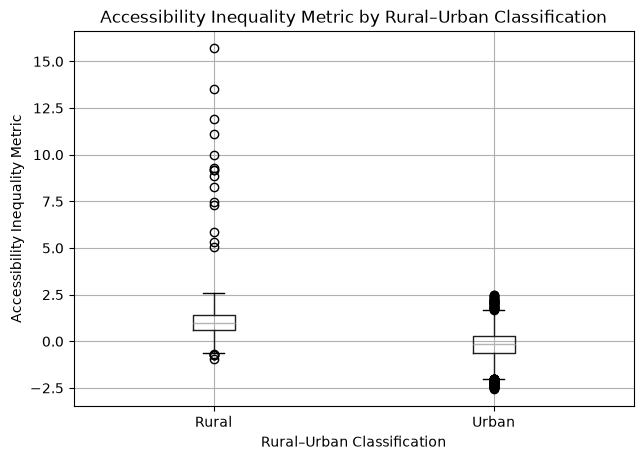

In [37]:
master_df.boxplot(
    column='accessibility_inequality_metric',
    by='Urban_rural_flag',
    figsize=(7, 5)
)

plt.title('Accessibility Inequality Metric by Rural–Urban Classification')
plt.suptitle('')
plt.xlabel('Rural–Urban Classification')
plt.ylabel('Accessibility Inequality Metric')
plt.show()

This boxplot highlights a stark structural divide in accessibility inequality between English rural & urban LSOAs. Notably, the rural category features severe, far-reaching upper outliers extending up to roughly 15.7, driving the positive skewness observed nationally & pointing to extreme spatial isolation in highly rural pockets. Conversely, while urban areas display a dense cluster of mild outliers around 2.5, their tight distribution shows that urban accessibility is generally bounded.

## Machine Learning

In [38]:
master_df.shape

(32747, 42)

In [39]:
master_df.columns.tolist()

['LSOA21CD',
 'employment_pt_time',
 'employment_car_time',
 'employment_pt_car_gap',
 'employment_pt_30min_pct',
 'FoodPTt',
 'FoodPT30pct',
 'FoodWalkt',
 'FoodCart',
 'Food_PT_Car_Gap',
 'GPPTt',
 'GPCart',
 'GPWalkt',
 'GPPT30pct',
 'GP_PT_Car_Gap',
 'HospPTt',
 'HospCart',
 'HospPT30pct',
 'Hosp_PT_Car_Gap',
 'TownPTt',
 'TownPT30pct',
 'Town_PT_Car_gap',
 'No_car_pct',
 'RUC21NM',
 'Urban_rural_flag',
 'rural_flag',
 'Observation',
 'population_density_log',
 'access_disadvantage',
 'car_access_pct',
 'car_access_z',
 'car_dependency',
 'cost_exposure_2022',
 'cost_exposure_2023',
 'access_disadvantage_z',
 'cost_exposure_2022_z',
 'cost_exposure_2023_z',
 'AIM_2022',
 'AIM_2023',
 'AIM_change',
 'accessibility_inequality_metric',
 'inequality_quintile']

The following are the **features** selected to be **Predictors**. It is done in a way to avoid Target(AIM) leakage. So all variables that directly influence AIM is removed along Food_PT_Car_Gap(as all values are zero and doesnt provide any valuable information)

In [40]:
target = 'accessibility_inequality_metric'

features = [
    # Transport characteristics not directly used in AIM
    'employment_pt_time',
    'employment_car_time',
    'employment_pt_car_gap',

    'FoodPTt',
    'FoodWalkt',

    'GPPTt',
    'GPCart',
    'GPWalkt',
    'GP_PT_Car_Gap',

    'HospPTt',
    'HospCart',
    'Hosp_PT_Car_Gap',

    'TownPTt',
    'Town_PT_Car_gap',

    # Socio-spatial characteristics
    'rural_flag',
    'population_density_log'
    
]

X = master_df[features].copy()
X.dtypes


employment_pt_time        float64
employment_car_time       float64
employment_pt_car_gap     float64
FoodPTt                   float64
FoodWalkt                 float64
GPPTt                     float64
GPCart                    float64
GPWalkt                   float64
GP_PT_Car_Gap             float64
HospPTt                   float64
HospCart                  float64
Hosp_PT_Car_Gap           float64
TownPTt                   float64
Town_PT_Car_gap           float64
rural_flag                  int64
population_density_log    float64
dtype: object

In [41]:
X_numeric = X.select_dtypes(include='number')

corr_matrix = X_numeric.corr()

corr_matrix.round(2)

,employment_pt_time,employment_car_time,employment_pt_car_gap,FoodPTt,FoodWalkt,GPPTt,GPCart,GPWalkt,GP_PT_Car_Gap,HospPTt,HospCart,Hosp_PT_Car_Gap,TownPTt,Town_PT_Car_gap,rural_flag,population_density_log
employment_pt_time,1.00,0.86,0.92,0.48,0.52,0.56,0.48,0.53,0.55,0.72,0.65,0.67,0.52,0.51,0.54,-0.59
employment_car_time,0.86,1.00,0.59,0.32,0.35,0.35,0.35,0.38,0.33,0.59,0.69,0.44,0.30,0.25,0.45,-0.46
employment_pt_car_gap,0.92,0.59,1.00,0.51,0.56,0.62,0.49,0.54,0.62,0.69,0.51,0.72,0.59,0.61,0.51,-0.58
FoodPTt,0.48,0.32,0.51,1.00,0.96,0.66,0.63,0.65,0.63,0.47,0.36,0.48,0.58,0.56,0.50,-0.64
FoodWalkt,0.52,0.35,0.56,0.96,1.00,0.68,0.64,0.69,0.66,0.52,0.39,0.53,0.60,0.60,0.57,-0.69
GPPTt,0.56,0.35,0.62,0.66,0.68,1.00,0.86,0.86,0.99,0.55,0.39,0.58,0.69,0.72,0.50,-0.65
GPCart,0.48,0.35,0.49,0.63,0.64,0.86,1.00,0.96,0.76,0.48,0.40,0.47,0.56,0.52,0.52,-0.64
GPWalkt,0.53,0.38,0.54,0.65,0.69,0.86,0.96,1.00,0.78,0.53,0.42,0.52,0.60,0.56,0.61,-0.70
GP_PT_Car_Gap,0.55,0.33,0.62,0.63,0.66,0.99,0.76,0.78,1.00,0.54,0.37,0.58,0.69,0.74,0.46,-0.62
HospPTt,0.72,0.59,0.69,0.47,0.52,0.55,0.48,0.53,0.54,1.00,0.87,0.95,0.52,0.51,0.54,-0.61


In [42]:
corr_with_aim = (
    master_df[
        list(X_numeric.columns) +
        ['accessibility_inequality_metric']
    ]
    .corr()['accessibility_inequality_metric']
    .drop('accessibility_inequality_metric')
    .sort_values(
        key=abs,
        ascending=False
    )
)

corr_with_aim

population_density_log   -0.718099
HospPTt                   0.708207
Hosp_PT_Car_Gap           0.679786
employment_pt_time        0.653328
GPPTt                     0.649524
employment_pt_car_gap     0.644824
TownPTt                   0.633772
GP_PT_Car_Gap             0.628518
GPWalkt                   0.617330
HospCart                  0.602588
GPCart                    0.594713
Town_PT_Car_gap           0.585162
FoodWalkt                 0.564282
FoodPTt                   0.549847
rural_flag                0.549573
employment_car_time       0.504620
Name: accessibility_inequality_metric, dtype: float64

In [43]:
# correlation between AIM components and metric
master_df[
    [
        'access_disadvantage_z',
        f"cost_exposure_{target_year}_z",
        'accessibility_inequality_metric'
    ]
].corr().round(3)

,access_disadvantage_z,cost_exposure_2022_z,accessibility_inequality_metric
access_disadvantage_z,1.000,0.463,0.855
cost_exposure_2022_z,0.463,1.000,0.855
accessibility_inequality_metric,0.855,0.855,1.000


Both sub-components: access_disadvantage_z (poor accessibility) and cost_exposure_2022_z (mobility cost pressure)-exhibit identical, strong positive correlations (0.855) with the final target variable, confirming that neither component artificially dominates the combined metric.

A moderate positive correlation (0.463) exists between physical access disadvantage and cost exposure. This demonstrates that while geographically isolated LSOAs naturally face higher fuel reliance, spatial distance and cost exposure are distinct dimensions that reinforce each other rather than measuring the exact same burden.

Model Training

In [44]:
y = master_df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (32747, 16)
y shape: (32747,)


Training the Datasets. Splitting of Datasets, 80% for Training Data and 20% for Testing Data

In [45]:
from sklearn.model_selection import train_test_split

# Each row is now one LSOA, so a plain random split is valid.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (26197, 16)  Test: (6550, 16)


Model Validation

R² measures the proportion of variation in AIM explained by the model, where a higher value indicates stronger predictive performance. MAE represents the average absolute prediction error, while RMSE gives greater weight to larger prediction errors. 

Linear Regression

In [46]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

lr = LinearRegression()
lr.fit(X_train, y_train)

pred_lr = lr.predict(X_test)

print("Linear Regression")
print("MAE:", mean_absolute_error(y_test, pred_lr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_lr)))
print("R²:", r2_score(y_test, pred_lr))

Linear Regression
MAE: 0.3570401528458668
RMSE: 0.46456006658547
R²: 0.6881635192670897


Random Forest Regressor

In [47]:
from sklearn.ensemble import RandomForestRegressor
import numpy as np

rf = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_leaf=20,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

pred_rf = rf.predict(X_test)

print("Random Forest")
print("MAE:", mean_absolute_error(y_test, pred_rf))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_rf)))
print("R²:", r2_score(y_test, pred_rf))

print("\nAvg leaves/tree:", round(np.mean([t.tree_.n_leaves for t in rf.estimators_])))
print("Avg depth:", round(np.mean([t.tree_.max_depth for t in rf.estimators_])))

Random Forest
MAE: 0.24938045850803756
RMSE: 0.3322378975555766
R²: 0.8405070431062244

Avg leaves/tree: 611
Avg depth: 15


Gradient Boosting Regressor

In [48]:
from sklearn.ensemble import GradientBoostingRegressor

gbr = GradientBoostingRegressor(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=3,
    random_state=42
)

gbr.fit(X_train, y_train)

pred_gbr = gbr.predict(X_test)

print("Gradient Boosting")
print("MAE:", mean_absolute_error(y_test, pred_gbr))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred_gbr)))
print("R²:", r2_score(y_test, pred_gbr))

Gradient Boosting
MAE: 0.2506627103278362
RMSE: 0.3298744092122063
R²: 0.8427681874907414


The model validation results show that Linear Regression performed comparatively weaker, whereas both Random Forest and Gradient Boosting achieved substantially better predictive accuracy. This indicates that the tree-based models captured the relationships underlying accessibility inequality more effectively than the linear model.

5 Fold Cross Validation

The Mean CV R² is simply the average R² across the five folds. It tells you the model's overall predictive performance across different subsets of the data.

SD(Standar Deviation) measures how much the five R² scores vary around their mean. In this context, it indicates the stability or consistency of model performance across the five folds.

In [49]:
from sklearn.model_selection import cross_val_score

models = {
    'Linear Regression': lr,
    'Random Forest': rf,
    'Gradient Boosting': gbr
}

for name, model in models.items():

    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring='r2'
    )

    print(name)
    print("CV R² scores:", scores)
    print("Mean CV R²:", scores.mean())
    print("SD:", scores.std())
    print()

Linear Regression
CV R² scores: [0.33359397 0.57276403 0.65101192 0.60836134 0.69299622]
Mean CV R²: 0.571745496519293
SD: 0.1257321055822184

Random Forest
CV R² scores: [0.71583178 0.65099248 0.7873325  0.79002093 0.84560802]
Mean CV R²: 0.7579571411114897
SD: 0.06751245774604579

Gradient Boosting
CV R² scores: [0.71922531 0.65498273 0.83088028 0.80002573 0.87497839]
Mean CV R²: 0.776018489586366
SD: 0.07906243806038578



Gradient Boosting has the best Mean CV R², while Random Forest has the lowest SD and therefore the most stable performance across folds. A lower SD is generally better, because it means the model performs more consistently when evaluated on different subsets of your LSOAs. Therefore Random Forest is chosen for Shap Analysis

## Shap Analysis

Shap Analysis is used to explain individual predictions by calculating how much each input feature contributed to the final model output compared to the baseline prediction.

In [50]:
!pip install shap

Since there are around 6550 test results, sample of 1000 observations was taken to reduce the exponential computational complexity of calculating exact Shapley values across all feature permutations, making model interpretation feasible for large datasets and complex algorithms.

In [51]:
# Combine X_test with corresponding AIM values
X_shap = X_test.copy()
X_shap['accessibility_inequality_metric'] = y_test.values

# Divide test observations into 5 AIM quintiles
X_shap['_AIM_group_'] = pd.qcut(
    X_shap['accessibility_inequality_metric'],
    q=5,
    labels=False,
    duplicates='drop'
)

# Sample 200 observations from each quintile
# 200 × 5 = 1000 observations total
X_shap = (
    X_shap
    .groupby('_AIM_group_', group_keys=False)
    .sample(n=200, random_state=42)
)

# Remove temporary columns
X_shap = X_shap.drop(
    columns=['accessibility_inequality_metric', '_AIM_group_']
)

print("SHAP sample shape:", X_shap.shape)

SHAP sample shape: (1000, 16)


In [52]:
import shap
explainer = shap.TreeExplainer(
    rf,
    feature_perturbation="tree_path_dependent"
)

shap_values = explainer.shap_values(
    X_shap,
    check_additivity=False
)

In [53]:
print(type(shap_values))

if isinstance(shap_values, list):
    print("Number of outputs:", len(shap_values))
    print("Shape of first output:", shap_values[0].shape)
else:
    print("SHAP values shape:", shap_values.shape)

<class 'numpy.ndarray'>
SHAP values shape: (1000, 16)


Shap analysis is done on 1000 randomly selected samples from test set with 16 features selected to be Predictors

Global Feature Importance

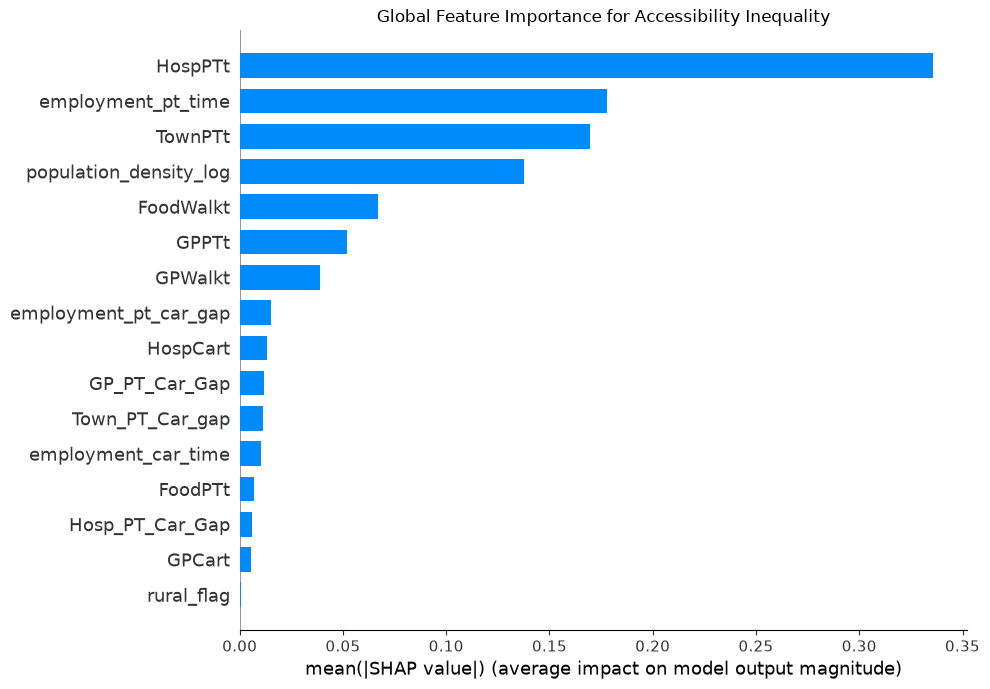

In [54]:
shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=False,
    plot_size =(10,7)
)

plt.title("Global Feature Importance for Accessibility Inequality")
plt.tight_layout()
plt.show()

Public transport travel time to major medical infrastructure (HospPTt) is by far the single dominant driver of transport vulnerability, possessing an average SHAP magnitude near 0.34-nearly double that of the next feature. Key employment access via public transport (employment_pt_time), town center transit times (TownPTt), and spatial compactness (population_density_log) constitute the secondary tier of influence, confirming that physical transit connectivity to essential services dictates overall inequality.
Local daily destinations (FoodWalkt, GPPTt) exert modest influence, while mode-gap disparities (_gap) and raw driving times (HospCart, GPCart) contribute minimally, proving that transit deficits rather than drive times dictate the model's predictions.

Summary Plot

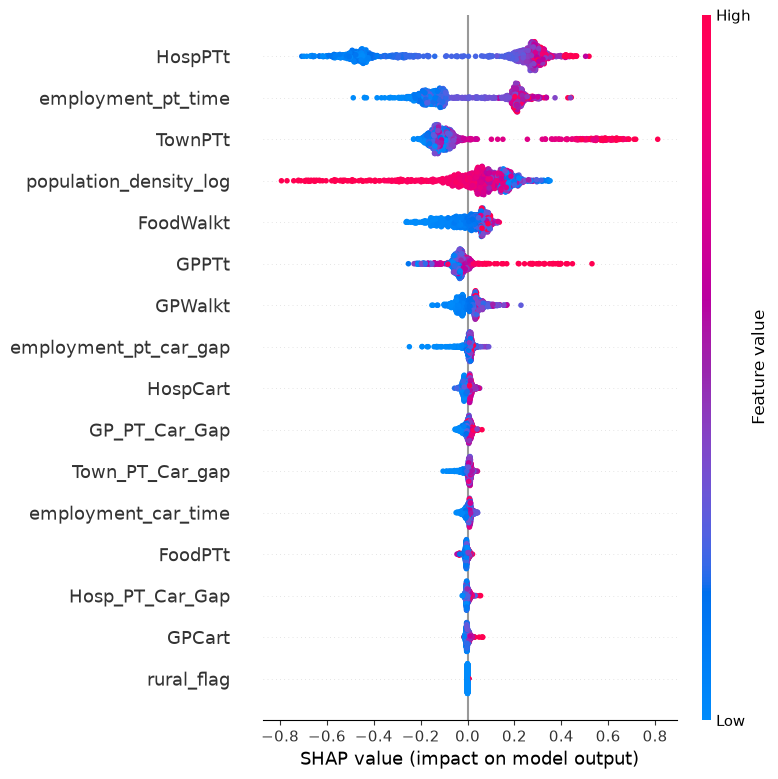

In [55]:
shap.summary_plot(
    shap_values,
    X_shap
)

High feature values (pink dots) for public transit times-such as hospital access (HospPTt), employment access (employment_pt_time), and town center access (TownPTt)-consistently yield positive SHAP values. Longer travel times by public transit directly elevate the predicted accessibility inequality score.
population_density_log displays a clear inverse relationship: high population density (pink dots) pushes the SHAP value below zero (reducing predicted inequality), whereas low population density (blue dots) pulls SHAP values heavily to the left, highlighting how spatial compactness acts as a protective factor against accessibility disadvantage.

Dependence Plot

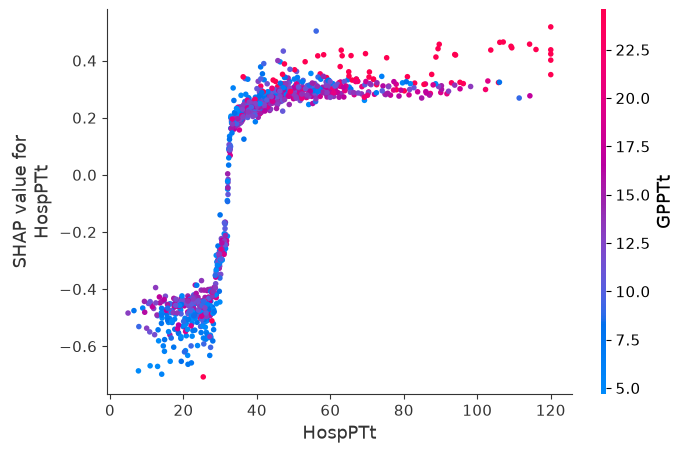

In [56]:
shap.dependence_plot(
    "HospPTt",
    shap_values,
    X_shap
)

The relationship between hospital public transport travel time (HospPTt) and predicted inequality is sharply non-linear. The SHAP value crosses the zero baseline at approximately 30 minutes, rapidly escalating from negative (protective) to a positive inequality contribution. Beyond ~40–45 minutes, the SHAP value plateaus around +0.3 to +0.35. This indicates a saturation effect where additional transit time to a hospital beyond this duration adds little incremental penalty to the predicted AIM score.

In [57]:
shap_importance = pd.DataFrame({
    'Feature': X_shap.columns,
    'Mean_Absolute_SHAP': np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    'Mean_Absolute_SHAP',
    ascending=False
)

shap_importance

,Feature,Mean_Absolute_SHAP
9,HospPTt,0.335583
0,employment_pt_time,0.177765
12,TownPTt,0.169402
15,population_density_log,0.137778
4,FoodWalkt,0.067052
5,GPPTt,0.051932
7,GPWalkt,0.039046
2,employment_pt_car_gap,0.015313
10,HospCart,0.013096
8,GP_PT_Car_Gap,0.011853


In [58]:
shap_importance['Importance_Percent'] = (
    shap_importance['Mean_Absolute_SHAP']
    / shap_importance['Mean_Absolute_SHAP'].sum()
    * 100
)

shap_importance

,Feature,Mean_Absolute_SHAP,Importance_Percent
9,HospPTt,0.335583,31.683885
0,employment_pt_time,0.177765,16.783629
12,TownPTt,0.169402,15.994042
15,population_density_log,0.137778,13.008286
4,FoodWalkt,0.067052,6.330661
5,GPPTt,0.051932,4.903122
7,GPWalkt,0.039046,3.686510
2,employment_pt_car_gap,0.015313,1.445778
10,HospCart,0.013096,1.236485
8,GP_PT_Car_Gap,0.011853,1.119120


HospPTt has 31.6% in terms of feature importance. The highest of all other predictors

Top 3 Features: SHAP dependence plots

In [59]:
top_features = shap_importance['Feature'].head(3).tolist()

print(top_features)

['HospPTt', 'employment_pt_time', 'TownPTt']


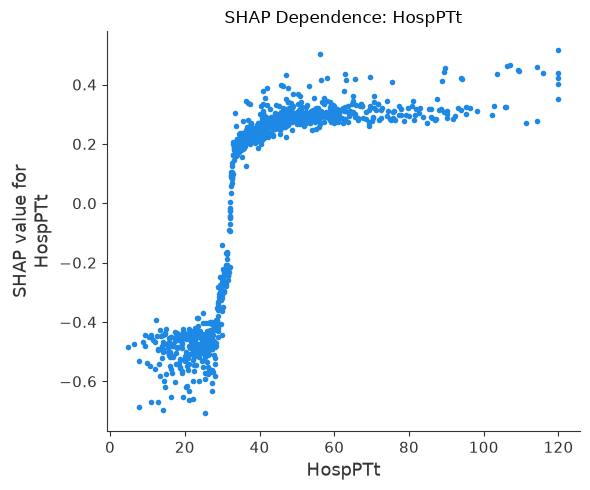

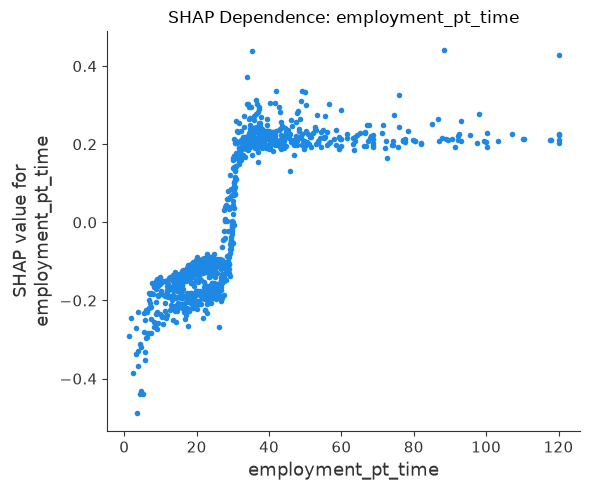

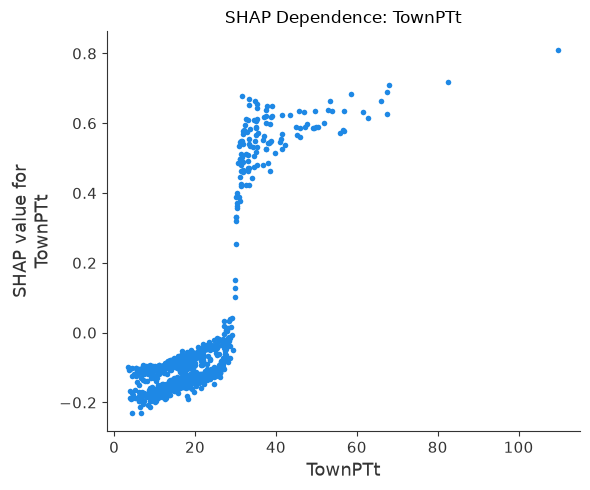

In [60]:
for feature in top_features:
    shap.dependence_plot(
        feature,
        shap_values,
        X_shap,
        interaction_index=None,
        show=False
    )

    plt.title(f"SHAP Dependence: {feature}")
    plt.tight_layout()
    plt.show()

All three key transit metrics display a consistent, non-linear 30-minute critical threshold, where public travel times under 30 minutes actively mitigate accessibility inequality, while times exceeding 30 minutes cause a steep, rapid jump into positive SHAP vulnerability scores. Beyond 35–40 minutes, hospital (HospPTt) and employment (employment_pt_time) accessibility metrics hit a clear saturation plateau near +0.3 and +0.2 respectively, meaning additional transit delays past this point contribute little incremental penalty. In contrast, town center travel times (TownPTt) continue rising past the threshold up to +0.8, showing that severe, spatial isolation from primary commercial hubs imposes the largest non-linear penalty on transport-vulnerable areas(LSOAs).

In [61]:
print("shap_values type:", type(shap_values))
print("shap_values shape:", np.shape(shap_values))
print("expected_value:", explainer.expected_value)
print("expected_value type:", type(explainer.expected_value))

shap_values type: <class 'numpy.ndarray'>
shap_values shape: (1000, 16)
expected_value: [0.0014352]
expected_value type: <class 'numpy.ndarray'>


SHAP Waterfall Plot

For this single LSOA with the highest predicted accessibility inequality score from the sample is selected and generates a local waterfall plot, explicitly breaking down how each feature's value shifted that specific instance's prediction away from the model's baseline average to its final target value.

Selected SHAP sample row: 969
Predicted AIM: 2.4598027088124774


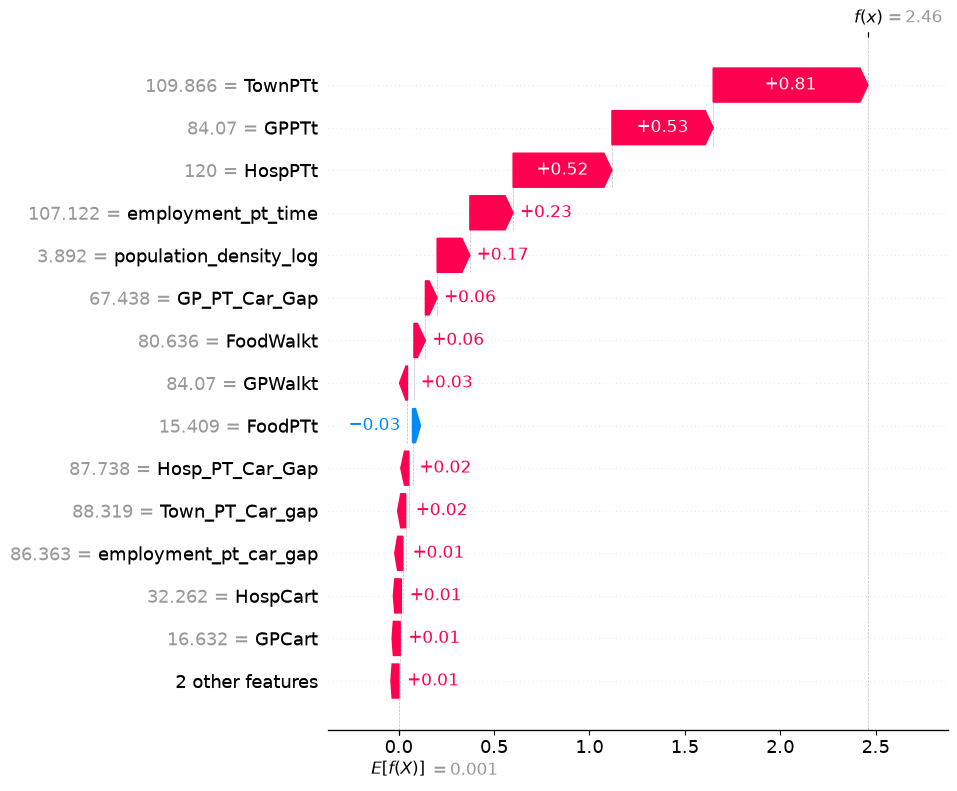

In [62]:
predictions = rf.predict(X_shap)

i = np.argmax(predictions)

print("Selected SHAP sample row:", i)
print("Predicted AIM:", predictions[i])

waterfall_explanation = shap.Explanation(
    values=shap_values[i],
    base_values=float(explainer.expected_value[0]),
    data=X_shap.iloc[i].values,
    feature_names=X_shap.columns.tolist()
)

shap.plots.waterfall(
    waterfall_explanation,
    max_display=15
)

Waterfall plot illustrates how local transport deficits push the area(LSOA) to an extreme predicted AIM score of 2.46, starting from a baseline average of E[f[X]] = 0.001


Primary Inequality Escalators: Severe transit isolation drives almost the entire positive shift. Public transport travel time to town centers (TownPTt = 109.87 min) contributes the largest single penalty of +0.81, followed closely by GP transit access (GPPTt = 84.07 min) at +0.53 and hospital transit time (HospPTt = 120 min) at +0.52. 

Secondary Structural Drivers: Longer public transport travel times to employment hubs (employment_pt_time = 107.12 min) and lower spatial compactness (population_density_log = 3.89) add further upward pressure of +0.23 and +0.17, respectively.

Minor Mitigating Factor: A short public transit duration to food stores (FoodPTt = 15.41 min) provides the only slight mitigating effect (-0.03), though it is vastly overwhelmed by the severe isolation across healthcare and regional hubs.